# Online Shoppers Purchasing Intention
## Supervised binary classification of online shopping sessions
### Paris-Saclay University, M1 Computer Science (2026-2027)

**Authors:**

- Illia VLASENKO *[M1 DiPaQ]  (22121663)*
- Théo DA SILVA PEREIRA *[M1 DKAI]  (22203352)*
- Alexander KUNITSYN *[M1 DiPaQ]  (22600913)*

## Table of contents

**1** Introduction
- **1.1** Motivation
- **1.2** Objective
- **1.3** Workflow

**2** Setup and data loading
- **2.1** Imports
- **2.2** Loading the dataset
- **2.3** Dataset structure

**3** Data quality assessment
- **3.1** Missing and duplicate values
- **3.2** Target distributions and data types

**4** Data analysis
- **4.1** Distribution of purchase outcomes
- **4.2** Sessions by visitor type and month
- **4.3** Purchase rates by visitor type and month
- **4.4** Numerical feature distributions
- **4.5** Mean feature values by purchase outcome

**5** Feature preparation and preprocessing
- **5.1** Features and target
- **5.2** Feature types
- **5.3** Stratified training/test split
- **5.4** Preprocessing pipelines

**6** Model training and selection
- **6.1** Baseline and validation protocol
- **6.2** Classifiers and hyperparameter search
- **6.3** Selection rule

**7** Evaluation of the results
- **7.1** Test set scores and generalisation
- **7.2** Confusion matrix for the selected model
- **7.3** ROC curves

**8** Discussion and conclusion
- **8.1** Limitations and future work

**9** Reproducibility

## 1. Introduction

### 1.1 Motivation

Understanding online customer behavior is an important challenge for e-commerce platforms. Predicting whether a visitor will make a purchase can help businesses understand shopping behavior.

### 1.2 Objective

We predict whether an online shopping session results in a purchase (represented in `Revenue`). This is a supervised binary classification task: independent variables describe a session, and the observed purchase outcome is the target label. We compare four classifiers against a dummy baseline.

### 1.3 Workflow

1. Explore and preprocess dataset
2. Train a classification model
3. Evaluate and compare model performance
4. Interpret the results

## 2. Setup and data loading

### 2.1 Imports

In [289]:
# Standard data science imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Section 6.1: baseline
from sklearn.dummy import DummyClassifier
# Section 6.1: metrics
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score
# Section 6.2: classifiers and hyperparameter search
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV
# Section 7: evaluation of the results
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve
)
from matplotlib.colors import LinearSegmentedColormap

# Fixed random seed for reproducible results
SEED = 42

### 2.2 Loading the dataset

In [290]:
# Data path as expected by the system
data_path = "data/online_shoppers_intention.csv"

# Read csv file into pandas.DataFrame
df = pd.read_csv(data_path)

# Print to see if the data looks alright
print("Dataset shape:", df.shape)
display(df.head())
df.info()

Dataset shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

### 2.3 Dataset structure

In [291]:
# What we can expect to see from the variables
# In what follows, code that can theoretically be left as one line will be formatted like this for the sake of lisibility.
display(
    df.describe(include="all").T # transpose for lisibility
)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,12330.0,NaN,NaN,NaN,2.315166,3.321784,0.0,0.0,1.0,4.0,27.0
Administrative_Duration,12330.0,NaN,NaN,NaN,80.818611,176.779107,0.0,0.0,7.5,93.25625,3398.75
Informational,12330.0,NaN,NaN,NaN,0.503569,1.270156,0.0,0.0,0.0,0.0,24.0
Informational_Duration,12330.0,NaN,NaN,NaN,34.472398,140.749294,0.0,0.0,0.0,0.0,2549.375
ProductRelated,12330.0,NaN,NaN,NaN,31.731468,44.475503,0.0,7.0,18.0,38.0,705.0
ProductRelated_Duration,12330.0,NaN,NaN,NaN,1194.74622,1913.669288,0.0,184.1375,598.936905,1464.157214,63973.52223
BounceRates,12330.0,NaN,NaN,NaN,0.022191,0.048488,0.0,0.0,0.003112,0.016813,0.2
ExitRates,12330.0,NaN,NaN,NaN,0.043073,0.048597,0.0,0.014286,0.025156,0.05,0.2
PageValues,12330.0,NaN,NaN,NaN,5.889258,18.568437,0.0,0.0,0.0,0.0,361.763742
SpecialDay,12330.0,NaN,NaN,NaN,0.061427,0.198917,0.0,0.0,0.0,0.0,1.0


As a sidenote, there are only 10 unique months in the dataset (no January, no April).

## 3. Data quality assessment

### 3.1 Missing and duplicate values

In [292]:
# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Missing values per column
print("\nMissing values per column:")
display(
    df
        .isna() # pd.df.isna detects missing values ("is NaN")
        .sum() # for each column, count missing entries
        .sort_values() # and sort the counts
        .to_frame(name="Missing values") # visual sugar
)

Duplicate rows: 125

Missing values per column:


,Missing values
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


Duplicate rows (125) are retained to preserve the original dataset: identical recorded features might occur in separate observations. Removing them would distort the frequency of such visits.
However, identical records may occur across the training/test split, which is a limitation of the evaluation. Removing or grouping duplicates would help mitigate this risk.

### 3.2 Target distribution and data types

In [293]:
# Revenue values (while these comments might not add much value in terms of actually commenting, they are a nice visual barrier between different sections of code. As such, we will continue to use them)
print("Revenue values:")
display(
    df["Revenue"]
        .value_counts(dropna=False) 
    # "do not exclude missing values from counts", as they are excluded by default
    # Here, not excluding missing values doesn't change much, since there are none.
        .reset_index(name="Frequency") # visual sugar; not to_frame because to_frame leaves "Revenue" and "Frequency" on different lines
)

# Data types
print("\nData types:")
display(
    df
        .dtypes # display data types
        .to_frame(name="Data type") # visual sugar
)

Revenue values:


,Revenue,Frequency
0,False,10422
1,True,1908



Data types:


,Data type
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64


Note that about 84.5% of entries are `False`. A dummy model that always guesses `False` will have an accuracy of 84.5%, despite being of very limited practical use. Therefore, this metric is not sufficient by itself.

## 4. Data analysis

### 4.1 Distribution of purchase outcomes

,Revenue,Frequency
0,False,10422
1,True,1908


,Revenue,Percentage
0,False,84.53
1,True,15.47


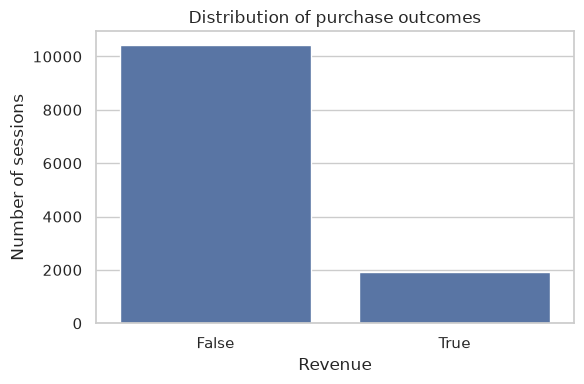

In [294]:
# Display purchase outcomes as a table
display(
    df["Revenue"]
        .value_counts()
        .reset_index(name="Frequency") # explained in previous cell
)

# Display percentages 
display(
    (df["Revenue"]
        .value_counts(normalize=True) * 100 # normalize to [0, 1]; multiply by 100
    )
        .round(2) # round to two decimal places, otherwise it's illegible
        .reset_index(name="Percentage")
)

# Plot the above as a bar chart
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="Revenue", ax=ax) # draw bars as a count plot
# Specify labels of axes
ax.set(
    title="Distribution of purchase outcomes",
    xlabel="Revenue",
    ylabel="Number of sessions"
)
plt.tight_layout()
plt.show()

### 4.2 Sessions by visitor type and month

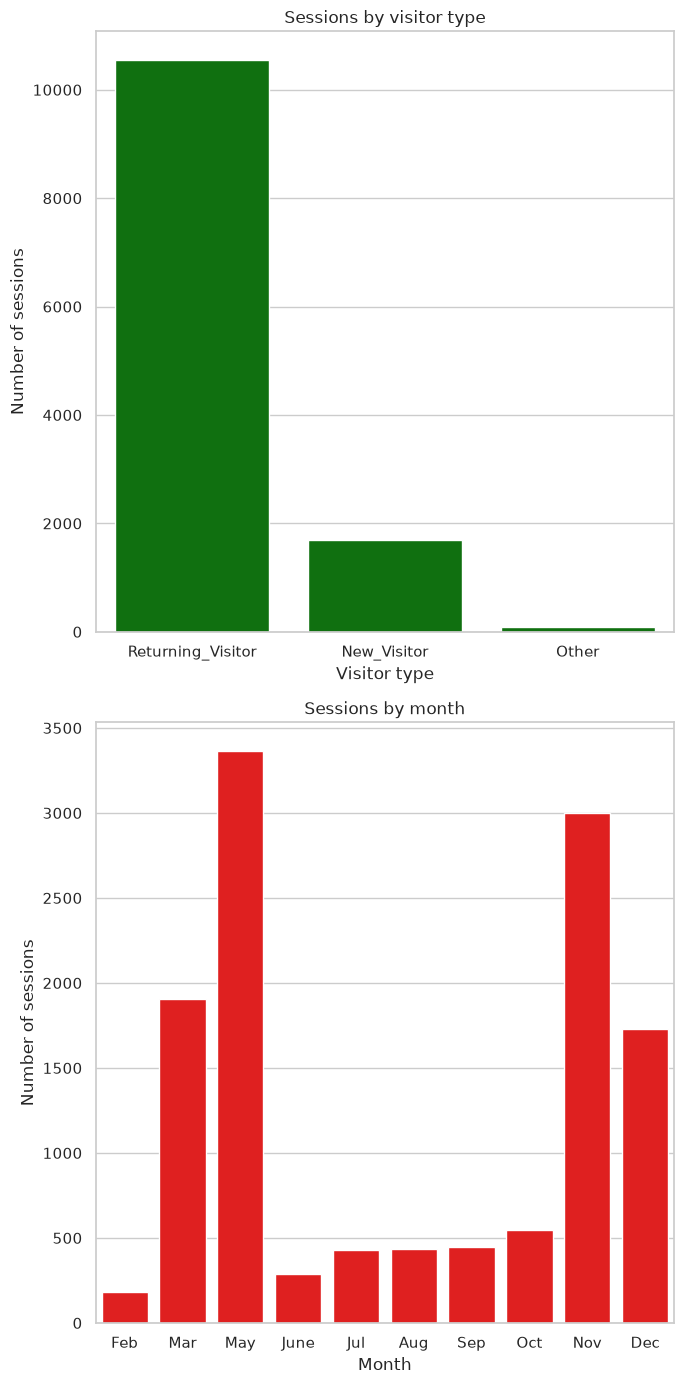

In [295]:
# Specify month order (we didn't find anything more elegant; without this, the months are in random order)
month_order = ["Jan", "Feb", "Mar", "Apr", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
observed_months = [month for month in month_order if month in df["Month"].unique()]

# Same as above
fig, axes = plt.subplots(2, 1, figsize=(7, 14))

sns.countplot(data=df, x="VisitorType", color="green", ax=axes[0])
axes[0].set(title="Sessions by visitor type", xlabel="Visitor type", ylabel="Number of sessions")

sns.countplot(data=df, x="Month", order=observed_months, color="red", ax=axes[1])
axes[1].set(title="Sessions by month", xlabel="Month", ylabel="Number of sessions")

plt.tight_layout()
plt.show()

### 4.3 Purchase rates by visitor type and month

In [296]:
# Group by visitor type, find the mean (of the Boolean variable Revenue; ergo, the average)
visitor_rates = df.groupby("VisitorType")["Revenue"].mean()

# Group by month,find the mean of Revenue, order in month order
month_rates = df.groupby("Month")["Revenue"].mean().reindex(observed_months)

display(
    visitor_rates
        .rename("Purchase rate")
        .to_frame()
        .reset_index(names="Visitor type")
)

display(
    month_rates
        .rename("Purchase rate")
        .to_frame()
        .reset_index(names="Month")
)

,Visitor type,Purchase rate
0,New_Visitor,0.249115
1,Other,0.188235
2,Returning_Visitor,0.139323


,Month,Purchase rate
0,Feb,0.016304
1,Mar,0.100682
2,May,0.108502
3,June,0.100694
4,Jul,0.152778
5,Aug,0.175520
6,Sep,0.191964
7,Oct,0.209472
8,Nov,0.253502
9,Dec,0.125072


The category `Other` is kept as in the dataset; one can't tell exactly what it means from the dataset alone.

### 4.4 Numerical feature distributions

In [297]:
# numeric_cols are defined to be the columns with numeric data types
numeric_cols = df.select_dtypes(include="number").columns.tolist()

display(
    df[numeric_cols]
        .describe()
        .T # transpose
)

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


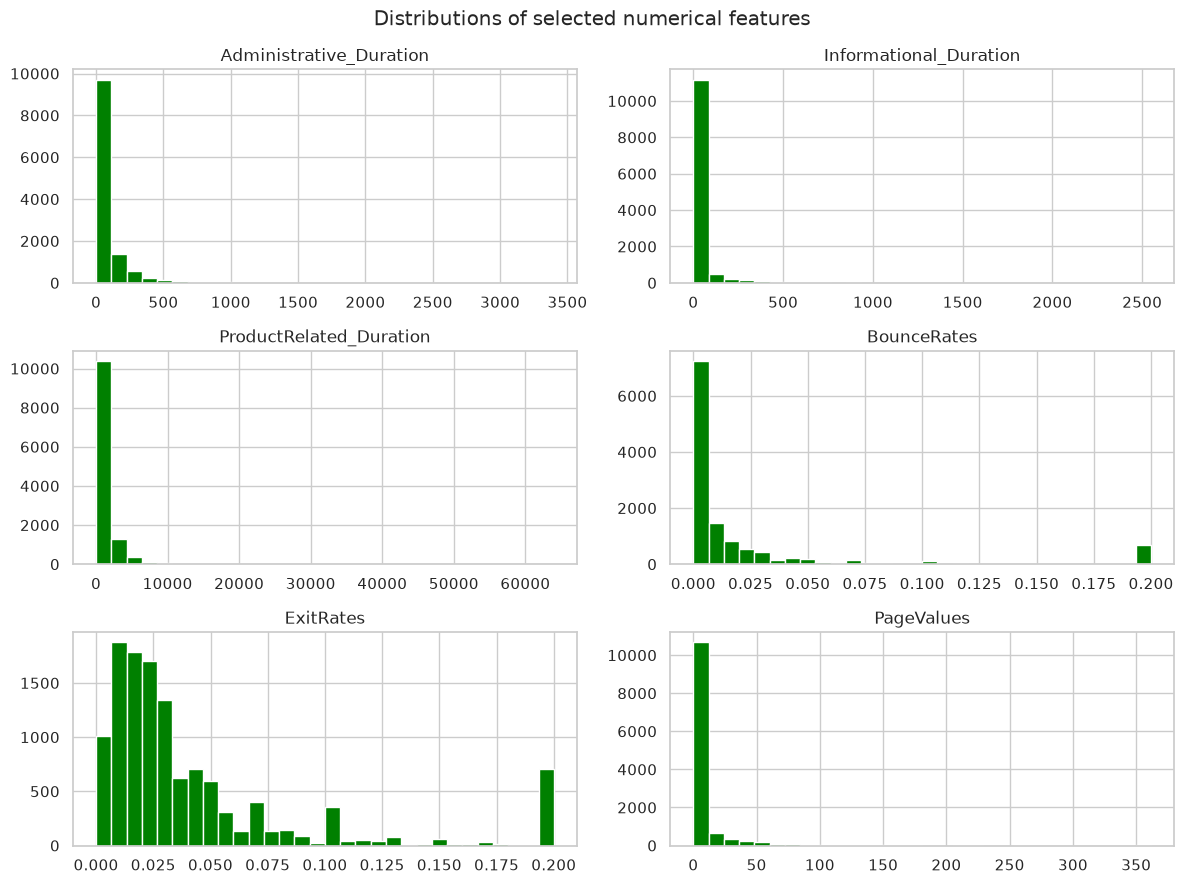

In [298]:
# Six features we'll plot
features_to_plot = [
    "Administrative_Duration", "Informational_Duration", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "PageValues"
]

df[features_to_plot].hist(figsize=(12, 9), bins=30, color="green")
plt.suptitle("Distributions of selected numerical features")
plt.tight_layout()
plt.show()

### 4.5 Mean feature values by purchase outcome

In [299]:
# Columns whose average values are compared between purchasing and non-purchasing sessions
comparison_features = [
    "PageValues", "ProductRelated_Duration", "ProductRelated", "BounceRates", "ExitRates"
]

display(
    df
        .groupby("Revenue")[comparison_features]
        .mean()
        .T # since it has become the standard already
        .rename(
            columns={False: "No purchase", True: "Purchase"}
        )
)

Revenue,No purchase,Purchase
PageValues,1.975998,27.264518
ProductRelated_Duration,1069.987809,1876.209615
ProductRelated,28.714642,48.210168
BounceRates,0.025317,0.005117
ExitRates,0.047378,0.019555


## 5. Feature preparation and preprocessing

### 5.1 Features and target

In [300]:
# Define target
target = "Revenue"

# Feature table: all columns except target
X = df.drop(columns=[target])
# Encode "no purchase" as 0 and "purchase" as 1.
y = df[target].astype(int)
assert set(y.unique()) == {0, 1}

# Print amount of features and the target classes
print("Features:", X.shape[1])
print("Target classes:", y.unique())

Features: 17
Target classes: [0 1]


### 5.2 Feature types

In [301]:
# Define categorical columns as non-numeric ones
categorical_cols = X.select_dtypes(include=["str", "category", "bool"]).columns.tolist()
# This was already done, but it doesn't hurt to redefine so that for the purposes of that which follows, it is defined in the same place.
numerical_cols = X.select_dtypes(include=np.number).columns.tolist()
print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)

# Check that the sets (lists in the code) are disjoint and that their direct sum is the original feature table
assert set(categorical_cols).isdisjoint(numerical_cols)
assert set(categorical_cols + numerical_cols) == set(X.columns)

Categorical columns: ['Month', 'VisitorType', 'Weekend']
Numerical columns: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']


### 5.3 Stratified training/test split

In [302]:
# Define the Xs and the ys for the train and test set
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=SEED, # cf. first cell
    stratify=y # preserve the same proportions of ys in the train and test sets
)

# Verify that we have reasonale results and that the split preserved similar proportions
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("Training purchase rate:", round(y_train.mean(), 4))
print("Test purchase rate:", round(y_test.mean(), 4))

Training set: (9864, 17)
Test set: (2466, 17)
Training purchase rate: 0.1547
Test purchase rate: 0.1549


### 5.4 Preprocessing pipelines

In [303]:
# Imputation replaces missing values
# "median" uses learned medians to impute
# StandardScaler scales according to z-scores:
#     z = (x - mu_train) / sigma_train
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# "most_frequent" uses learned modes to impute
# OneHotEncoder converts categorical values into numerical indicator columns
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Applies preprocessing procedure
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numerical_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

## 6. Model training and selection

### 6.1 Baseline and validation protocol

The dummy classifier gives us a baseline: it shows how well we can do without using any information about the sessions. To compare the other models, we divide the training data into five groups (folds), keeping a similar proportion of purchases in each. We train on four groups and check performance on the remaining one, repeating this until every group has been used for validation.

We choose the model with the highest average precision (AP). This rewards models that give purchasing sessions higher scores than non-purchasing sessions. Precision, recall and F1 tell us how good the model’s final decisions are. AP and ROC AUC (receiver operating characteristic; area under curve) also tell us how well it ranks purchasing sessions above non-purchasing sessions.

In [304]:
# Create classifier
dummy_model = DummyClassifier(strategy="prior")
# Fit classifier (it fully ignores feature values)
dummy_model.fit(X_train, y_train)

# Show class labels and their learned proportions
dummy_distribution = pd.Series(
    dummy_model.class_prior_, 
    index=dummy_model.classes_,
    name="Training class proportion"
)
display(
    dummy_distribution
        .rename_axis("Class labels")
        .to_frame()
        .reset_index()
)

,Class labels,Training class proportion
0,0,0.845296
1,1,0.154704


In [305]:
# We will take five training sessions to inspect the model's behaviour
example_sessions = X_train.iloc[:5]
example_predictions = dummy_model.predict(example_sessions)
# Create probabilities for each class
example_probabilities = dummy_model.predict_proba(example_sessions)

# One should see the same prediction for every session and the same probability vector for every session
print("Class order:", dummy_model.classes_)
print("Predicted labels:", example_predictions)
print("Predicted probabilities:\n", example_probabilities)

Class order: [0 1]
Predicted labels: [0 0 0 0 0]
Predicted probabilities:
 [[0.84529603 0.15470397]
 [0.84529603 0.15470397]
 [0.84529603 0.15470397]
 [0.84529603 0.15470397]
 [0.84529603 0.15470397]]


As we see, the dummy model indeed predicts the same thing every time.

We will now define the primary metrics that will be recorded for every model. Take $\text{TP}$ to mean (amount of) "true positives", $\text{TN}$ to mean "true negatives", $\text{FP}$ to mean "false positives" (Type I error), and $\text{FN}$ to mean "false negatives" (Type II error).
1. Accuracy: what proportion of *all* predictions are correct?
$$
\text{Accuracy} := \frac{\text{TP \(+\) TN}}{\text{TP \(+\) TN \(+\) FP \(+\) FN}}
$$
2. Average precision: how good is the precision-recall trade-off across score thresholds?
$$
\text{AP} := \sum_{n=1}^{K}(R_n - R_{n-1})P_n
$$
Here, $K$ is the number of prediction thresholds ($0.9$, $0.8$, $0.7$, $\ldots$; the cutoffs at which a `False` turns into a `True`) evaluated, $R_n$ is the recall when using the $n$th threshold (therefore, $R_n - R_{n-1}$ is the increase in recall over a threshold), $P_n$ is the precision at the $n$th threshold.
3. ROC-AUC: area under the receiver operating characteristic curve, measures how well the model tells the two classes apart.
4. Precision: what proportion of *predicted positives* are correct?
$$
\text{Precision} := \frac{\text{TP}}{\text{TP \(+\) FP}}
$$
5. Recall (sensitivity rate; true positive rate): what propostion of *actual positives* are identified?
$$
\text{Recall} := \frac{\text{TP}}{\text{TP \(+\) FN}}
$$
6. F1: harmonic mean of precision and recall
$$
\text{F1} := 2\times\frac{\text{Precision \(\times\) Recall}}{\text{Precision \(+\) Recall}}
$$

We chose these six metrics to cover overall correctness and purchase detection, with AP being the main criterion.

In [306]:
# cv := cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


# Average precision is the primary selection metric
# make_scorer() adapts label-based metrics to the cross-validation interface
# zero_division=0 reports zero instead of breaking down
scoring = {
    "accuracy": "accuracy",
    "ap": "average_precision",
    "roc_auc": "roc_auc",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
}

We will now evaluate the dummy model through cross-validation and establish reference scores.

In [307]:
dummy_cv = cross_validate(
    estimator=dummy_model,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    # record fitting-data scores; used later to compare training and validation performance
    return_train_score=True
)

# Summarise the five validation scores for each metric;
# build a df from two dictionaries keyed by metric name
dummy_summary = pd.DataFrame({
    "mean_validation_score": {
        metric: dummy_cv[f"test_{metric}"].mean() for metric in scoring
    },
    "std_across_folds": {
        metric: dummy_cv[f"test_{metric}"].std() for metric in scoring
    },
})
display(dummy_summary.round(4))

,mean_validation_score,std_across_folds
accuracy,0.8453,0.0002
ap,0.1547,0.0002
roc_auc,0.5000,0.0000
precision,0.0000,0.0000
recall,0.0000,0.0000
f1,0.0000,0.0000


### 6.2 Classifiers and hyperparameter search

We compare logistic regression, a decision tree, a random forest and gradient boosting. Each search evaluates eight hyperparameter configurations (starting from candidate values) with the same five-fold process, then refits its selected configuration on the full training set. The model with the highest mean validation AP is selected before test evaluation.

In [308]:
# Each entry contains:
# - an unfitted classifier
# - a dictionary of hyperparameter values to investigate
experiments = {
    "Logistic regression": (
        LogisticRegression(
            max_iter=3000,
            random_state=SEED
        ),
        {
            # smaller C means stronger regularisation
            "model__C": [0.01, 0.1, 1, 10],
            # compare ordinary fitting with class-weighted fitting
            "model__class_weight": [None, "balanced"]
        }
    ),

    "Decision tree": (
        DecisionTreeClassifier(random_state=SEED),
        {
            # limit the number of split levels. None allows growth without an explicit depth limit
            "model__max_depth": [3, 5, 8, None],
            # larger leaves prevent very specific, small-sample rules
            "model__min_samples_leaf": [1, 5, 20],
            "model__class_weight": [None, "balanced"]
        }
    ),

    "Random forest": (
        RandomForestClassifier(random_state=SEED),
        {
            # number of trees in the forest
            "model__n_estimators": [200, 400],
            # as above
            "model__max_depth": [8, 15, None],
            "model__min_samples_leaf": [1, 5, 15],
            # number/fraction of features considered at each split
            "model__max_features": ["sqrt", 0.7],
            "model__class_weight": [None, "balanced"]
        }
    ),

    "Gradient boosting": (
        GradientBoostingClassifier(random_state=SEED),
        {
            # number of sequential boosting stages
            "model__n_estimators": [100, 200],
            # contribution of each newly added tree
            "model__learning_rate": [0.03, 0.1],
            # complexity of each individual tree
            "model__max_depth": [2, 3],
            "model__min_samples_leaf": [5, 20],
            # fraction of training examples used at each stage
            "model__subsample": [0.8, 1.0]
        }
    )
}

In [309]:
# Keep the fitted search object for every model
searches = {}

# Start the comparison table with the dummy baseline
results_rows = [{
    "model": "Dummy",
    "train_AP": dummy_cv["train_ap"].mean(),
    "validation_AP": dummy_cv["test_ap"].mean(),
    "validation_AP_std": dummy_cv["test_ap"].std(),
    "validation_accuracy": dummy_cv["test_accuracy"].mean(),
    "validation_ROC_AUC": dummy_cv["test_roc_auc"].mean(),
    "validation_precision": dummy_cv["test_precision"].mean(),
    "validation_recall": dummy_cv["test_recall"].mean(),
    "validation_F1": dummy_cv["test_f1"].mean(),
    "best_params": {}
}]

for model_name, (classifier, parameter_space) in experiments.items():
    print(f"Training and tuning: {model_name}")
    # clone() copies the configuration without any fitted state. Each model therefore receives its own preprocessing object
    model_pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", clone(classifier))
    ])

    search = RandomizedSearchCV(
        estimator=model_pipeline,
        param_distributions=parameter_space,

        # evaluate eight candidate configurations per model
        n_iter=8,

        # record all previously defined metrics
        scoring=scoring,

        # select the best configuration using validation AP, then fit it again on the entire training set
        refit="ap",

        # use the same fold-generation settings for every model
        cv=cv,

        # fix reproducibility
        random_state=SEED,

        # record training scores to help identify overfitting
        return_train_score=True,
    )

    # this performs cross-validation, selects the best settings, and refits the selected pipeline
    # X_test and y_test are not involved
    search.fit(X_train, y_train)

    searches[model_name] = search

    # cv_results_ contains a result row for every tested configuration
    # best_index_ identifies the configuration selected by validation AP
    best_index = search.best_index_
    cv_results = search.cv_results_

    results_rows.append({
        "model": model_name,
        "train_AP": cv_results["mean_train_ap"][best_index],
        "validation_AP": cv_results["mean_test_ap"][best_index],
        "validation_AP_std": cv_results["std_test_ap"][best_index],
        "validation_accuracy": cv_results["mean_test_accuracy"][best_index],
        "validation_ROC_AUC": cv_results["mean_test_roc_auc"][best_index],
        "validation_precision": cv_results["mean_test_precision"][best_index],
        "validation_recall": cv_results["mean_test_recall"][best_index],
        "validation_F1": cv_results["mean_test_f1"][best_index],
        "best_params": search.best_params_
    })

Training and tuning: Logistic regression
Training and tuning: Decision tree
Training and tuning: Random forest
Training and tuning: Gradient boosting


In [310]:
# 4 models * 8 configurations * 5 folds = 160 validation fits
# RandomizedSearchCV also refits each selected configuration on all training data
print("Candidate/fold fits:", len(experiments) * 8 * cv.get_n_splits())

Candidate/fold fits: 160


In [311]:
# Compare models using validation scores only
comparison = pd.DataFrame(results_rows)

# Sort models from highest to lowest mean validation AP
comparison = (
    comparison
    .sort_values("validation_AP", ascending=False)
    .reset_index(drop=True)
)

# A large positive gap can indicate overfitting
comparison["AP_train_validation_gap"] = (
    comparison["train_AP"] - comparison["validation_AP"]
)

# Show numerical results separately from the parameter dictionaries
display(
    comparison.drop(columns="best_params").round(4)
)

# Print the chosen settings in a more readable format
for _, row in comparison.iterrows():
    print(f"\n{row['model']}")
    print(row["best_params"])

,model,train_AP,validation_AP,validation_AP_std,validation_accuracy,validation_ROC_AUC,validation_precision,validation_recall,validation_F1,AP_train_validation_gap
0,Random forest,0.8418,0.7548,0.0153,0.9055,0.9329,0.7377,0.6055,0.6646,0.0870
1,Gradient boosting,0.8015,0.7512,0.0154,0.9040,0.9327,0.7265,0.6101,0.6629,0.0503
2,Decision tree,0.8098,0.6903,0.0250,0.8967,0.9060,0.7070,0.5747,0.6328,0.1195
3,Logistic regression,0.6624,0.6594,0.0173,0.8612,0.9058,0.5365,0.7621,0.6297,0.0030
4,Dummy,0.1547,0.1547,0.0002,0.8453,0.5000,0.0000,0.0000,0.0000,0.0000



Random forest
{'model__n_estimators': 200, 'model__min_samples_leaf': 15, 'model__max_features': 0.7, 'model__max_depth': 8, 'model__class_weight': None}

Gradient boosting
{'model__subsample': 1.0, 'model__n_estimators': 200, 'model__min_samples_leaf': 20, 'model__max_depth': 3, 'model__learning_rate': 0.03}

Decision tree
{'model__min_samples_leaf': 20, 'model__max_depth': 8, 'model__class_weight': None}

Logistic regression
{'model__class_weight': 'balanced', 'model__C': 1}

Dummy
{}


In [312]:
# Exclude the dummy when choosing among the real classifiers
real_model_results = comparison[comparison["model"] != "Dummy"]

# We will now pick out the best model
# The table is already sorted by validation AP
best_name = real_model_results.iloc[0]["model"]
best_pipeline = searches[best_name].best_estimator_
best_ap = searches[best_name].best_score_
dummy_ap = dummy_cv["test_ap"].mean()

print("Selected real model:", best_name)
print("Mean validation AP:", round(best_ap, 4))
print("Dummy validation AP:", round(dummy_ap, 4))
print("Selected hyperparameters:")
print(searches[best_name].best_params_)

if best_ap <= dummy_ap:
    print("Warning: the dummy classifier did better; something isn't right")

Selected real model: Random forest
Mean validation AP: 0.7548
Dummy validation AP: 0.1547
Selected hyperparameters:
{'model__n_estimators': 200, 'model__min_samples_leaf': 15, 'model__max_features': 0.7, 'model__max_depth': 8, 'model__class_weight': None}


### 6.3 Selection rule

We choose the classifier with the highest average validation AP. Small differences between models may not mean that one is genuinely better. The standard deviation shows how much the scores vary across folds; it does not necessarily mean that one model outperforms another.

## 7. Evaluation of the results

In [313]:
# Cosmetics for what follows
CLASS_NAMES = ["No purchase", "Purchase"]

# Nice colours
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
MODEL_COLORS = {
    "Random forest": PALETTE[0],
    "Gradient boosting": PALETTE[1],
    "Logistic regression": PALETTE[2],
    "Decision tree": PALETTE[3]
}

INK = "#0b0b0b"
MUTED = "#898781"
GRID = "#e1e0d9"

BLUE_RAMP = LinearSegmentedColormap.from_list(
    "blue_ramp",
    ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)

### 7.1 Test set scores and generalisation

The table below shows the best configurations for all four model families and the baseline.

In [314]:
# Define a reusable function so that every model is evaluated in the same way
def classification_metrics(y_true, y_pred, y_score):
    """
    Inputs:
        y_true: actual outcomes, 0 or 1
        y_pred: predicted outcomes, 0 or 1
        y_score: predicted probabilities for class 1 (purchase)
    Returns:
        Dict[str:float], one value for each evaluation metric
    """

    # we are building a 2*2 confusion matrix:
    # [[true negatives,    false positives]
    #  [false negatives,    true positives]]
    # labels=[0, 1] keeps the 2*2 layout even if a class is never predicted
    tn, fp, fn, tp = confusion_matrix(
        y_true, 
        y_pred, 
        labels=[0, 1]
    ).ravel()

    # return a dictionary containing one value for each evaluation metric (cf. section 6.1 for an introduction)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "specificity": tn / (tn + fp), # the only new metric introduced here for completeness
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_score),
        "ap": average_precision_score(y_true, y_score)
    }

# Retrieve each search's selected (best) pipeline
fitted_models = {
    name: searches[name].best_estimator_
    for name in comparison["model"]
    if name in searches
}

# Generate purchase/non-purchase predictions for every test session
test_pred = {
    name: model.predict(X_test) 
    for name, model in fitted_models.items()
}
# Generate purchase probabilities for every test session
test_proba = {
    name: model.predict_proba(X_test)[:, 1] # selects probability column for class 1 in fitted models
    for name, model in fitted_models.items()
}

# Generate predictions and probabilities from the baseline model
dummy_pred = dummy_model.predict(X_test)
dummy_proba = dummy_model.predict_proba(X_test)[:, 1]

# Calculate test metrics for each tuned classifier
# Dict[str: Dict[str: float]]
rows = {
    name: classification_metrics(y_test, test_pred[name], test_proba[name])
    for name in fitted_models
}
# Add baseline to the dictionary
rows["Dummy"] = classification_metrics(y_test, dummy_pred, dummy_proba)

# Convert dictionary into a table
test_scores = pd.DataFrame(rows).T
test_scores.index.name = "model"

# Display
print("Test sessions:", len(y_test), "| purchases:", int(y_test.sum()))
print("Selected model:", best_name)
# Round displayed scores to 3 d.p.
display(test_scores.round(3))

Test sessions: 2466 | purchases: 382
Selected model: Random forest


,accuracy,precision,recall,specificity,f1,roc_auc,ap
model,,,,,,,
Random forest,0.901,0.721,0.589,0.958,0.648,0.930,0.744
Gradient boosting,0.901,0.718,0.594,0.957,0.650,0.929,0.744
Decision tree,0.897,0.712,0.563,0.958,0.629,0.908,0.682
Logistic regression,0.850,0.511,0.749,0.869,0.607,0.896,0.626
Dummy,0.845,0.000,0.000,1.000,0.000,0.500,0.155


In [315]:
# Use model names as row labels
cv_scores = comparison.set_index("model")

# Combine c-v results with final test results
generalization = pd.DataFrame({
    # AP on train table
    "train_AP": cv_scores["train_AP"],
    # AP on held-out validation table
    "validation_AP": cv_scores["validation_AP"],
    # AP on test table
    "test_AP": test_scores["ap"],
    # ROC-AUC on held-out validation
    "validation_ROC_AUC": cv_scores["validation_ROC_AUC"],
    # ROC-AUC on test
    "test_ROC_AUC": test_scores["roc_auc"],
    # F1 on validation
    "validation_F1": cv_scores["validation_F1"],
    # F1 on test
    "test_F1": test_scores["f1"]
}).reindex(comparison["model"])

# Measure the change from validation AP to test AP
# Negative value means AP was lower on the test set (to be expected; you'll always be better on the data you trained on)
generalization["test_minus_validation_AP"] = (
    generalization["test_AP"] - generalization["validation_AP"]
)
generalization.index.name = "model"

# Round to 3 d.p.
display(generalization.round(3))

,train_AP,validation_AP,test_AP,validation_ROC_AUC,test_ROC_AUC,validation_F1,test_F1,test_minus_validation_AP
model,,,,,,,,
Random forest,0.842,0.755,0.744,0.933,0.930,0.665,0.648,-0.011
Gradient boosting,0.801,0.751,0.744,0.933,0.929,0.663,0.650,-0.007
Decision tree,0.810,0.690,0.682,0.906,0.908,0.633,0.629,-0.009
Logistic regression,0.662,0.659,0.626,0.906,0.896,0.630,0.607,-0.034
Dummy,0.155,0.155,0.155,0.500,0.500,0.000,0.000,0.000


As mentioned in the comments to the code, a lower test score is to be expected, however a significant drop-off would be reason to investigate (the model might have overfitted; the test set might have been unrepresentative, et cetera).

### 7.2 Confusion matrix for the selected model

The confusion matrix represents represents which decisions the classifier got right and wrong. Rows represent actual outcomes, columns represent predicted outcomes. Here, we display counts and percentages for clarity.

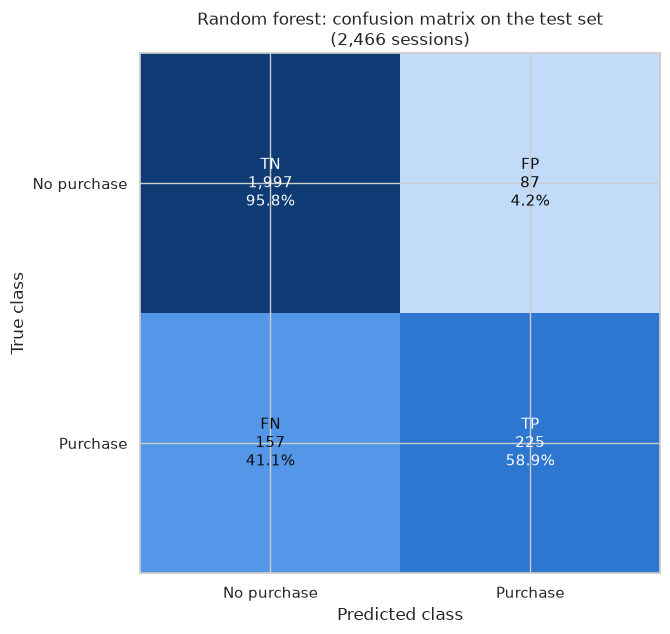

In [316]:
# Count correct and incorrect predictions for the best classifier
counts = confusion_matrix(
    y_test,
    test_pred[best_name],
    labels=[0, 1]
)

# Converts counts into propostions.
row_share = counts / counts.sum(axis=1, keepdims=True) # keepdims=True keeps totals in a column

CELL_NAMES = [["TN", "FP"], ["FN", "TP"]]

# Create plotting area
fig, ax = plt.subplots(figsize=(7, 6.5))

# Colour cells accordingly to their percentages
ConfusionMatrixDisplay(row_share, display_labels=CLASS_NAMES).plot(
    ax=ax,
    cmap=BLUE_RAMP,
    colorbar=False,
    include_values=False,
    im_kw={"vmin": 0, "vmax": 1}
)

# Add annotation to each cell
for i in range(2):
    for j in range(2):
        ax.text(
            j, i,
            f"{CELL_NAMES[i][j]}\n{counts[i, j]:,}\n{row_share[i, j]:.1%}",
            ha="center",
            va="center",
            fontsize=11,
            color="white" if row_share[i, j] > 0.5 else INK
        )

# Add labels and titles
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title(f"{best_name}: confusion matrix on the test set\n({len(y_test):,} sessions)")
plt.tight_layout()
plt.show()

False positives are non-purchasing sessions incorrectly flagged as purchases. False negatives are actual purchases that the model missed. The correctly-classified percentage in the purchase row is recall; the correctly classified percentage in the non-purchase row is specificity.

### 7.3 ROC curves

The ROC curves show what happens when we make the model more or less willing to predict a purchase. The horizontal axis shows how often it raises a false alarm, while the vertical axis shows how many actual purchases it catches. Each circle marks the results using the model’s default settings.

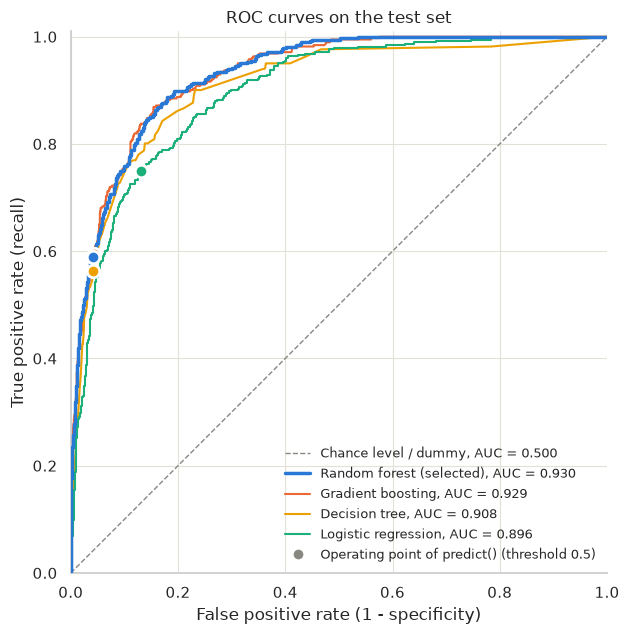

In [317]:
# Create a rectangular plotting area
fig, ax = plt.subplots(figsize=(7, 6.5))

# Reference (dummy) diagonal
ax.plot(
    [0, 1], [0, 1],
    color=MUTED, linewidth=1, linestyle="--",
    label="Chance level / dummy, AUC = 0.500"
)

# Draw one curve per classifier
for name, proba in test_proba.items():
    # calculate false-positive and true-positive rates at different thresholds
    # we don't need the thresholds themselves, hence the use of _
    fpr, tpr, _ = roc_curve(y_test, proba)
    # identify model selected by validation AP to make it stand out visually
    is_selected = name == best_name
    # use a model's assigned colour or a neutral one if none is assigned
    color = MODEL_COLORS.get(name, MUTED)

    # plotting functions
    ax.plot(
        fpr, tpr,
        color=color,
        # make the line of the selected model thicker
        linewidth=2.5 if is_selected else 1.5,
        zorder=3 if is_selected else 2,
        # show model name, selection status and test ROC-AUC
        label=f"{name}{' (selected)' if is_selected else ''}, "
              f"AUC = {test_scores.loc[name, 'roc_auc']:.3f}"
    )
    # mark operating points obtained from the model's default predictions
    ax.plot(
        # false-positive rate = 1 - specificity
        1 - test_scores.loc[name, "specificity"],
        # true positive rate is recall
        test_scores.loc[name, "recall"],

        # draw a point without connecting it to another point
        marker="o", 
        markersize=9, 
        linestyle="none",
        color=color,
        markeredgecolor="white",
        markeredgewidth=2,
        zorder=5 if is_selected else 4
    )

# Legend entry for circular markers
ax.plot(
    [], [],
    marker="o", markersize=9, linestyle="none",
    color=MUTED, markeredgecolor="white", markeredgewidth=2,
    label="Operating point of predict() (threshold 0.5)"
)

ax.set_xlim(0, 1) # \in [0, 1]
ax.set_ylim(0, 1.01) # leave a bit of space so that the top of curve remains visible
ax.set_aspect("equal") # use same visual scale on both axes

# Labels, legend
ax.set_xlabel("False positive rate (1 - specificity)")
ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC curves on the test set")
ax.legend(loc="lower right", frameon=False, fontsize=9)

# Add light grid
ax.grid(color=GRID, linewidth=0.8)
ax.set_axisbelow(True)

# Remove borders
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

## 8. Discussion and conclusion

In the supplied execution, the random forest had the highest mean validation AP (approximately 0.755), followed closely by gradient boosting (approximately 0.751). The random forest was therefore selected before consulting the test scores. On the held-out test set, its AP was approximately 0.744 and its ROC AUC approximately 0.930, compared with approximately 0.155 and 0.500 for the dummy baseline.

At its default prediction rule, the selected model achieved a precision of approximately 0.721 and a recall of 0.589. Thus, its purchase predictions were substantially more informative than the baseline, but it still missed a meaningful share of purchase sessions. Gradient boosting produced very similar results; the random forest is not universally superior.

### 8.1 Limitations and future work

- Duplicate records were retained; an alternative duplicate-aware evaluation would test the robustness of the results.
- The exploratory analysis uses the complete dataset. No explicit feature selection was based on it, but a stricter future study can be done to the test data before exploration.
- Integer-coded categorical variables were treated as numerical to preserve the original data. Their categorical encoding could be evaluated separately using training-only validation.
- Session-level features describe recorded sessions. Before deployment, verify that every predictor, especially `PageValues`, is available at the intended prediction time and does not contain information unavailable before the outcome.
- Our random split does not tell us how well the model would work in future months or on another website. To test future performance, we would need enough date information to train on earlier sessions and evaluate on later ones.
- We did not explore changing the purchase cutoff, checking how closely predicted probabilities match actual purchase rates, or weighing the costs of false alarms and missed purchases. Any cutoff adjustments should use training or validation data, leaving the test set for final evaluation.

Overall, the recorded experiment supports the usefulness of session characteristics for distinguishing purchase from non-purchase sessions within this split. We can't make causal inferences from the results.

## 9. Reproducibility

Place the supplied CSV in a `./data/` subdirectory, then restart the kernel and run all cells in order. The workflow uses pandas, NumPy, Matplotlib, seaborn and scikit-learn. The random seed is fixed at 42. The full search performs 160 candidate/fold fits plus four final refits, and may take several minutes.

Getting exactly the same results may depend on the package versions used, which are not recorded here.